=== FULL MATCH FANTASY LEADERBOARD ===
 player_id player_name team role  bat_pts  bowl_pts  field_pts  total_points
       105    H Pandya  IND   AR       49        87          8           148
       102     V Kohli  IND  BAT      108         0          8           120
       111     A Singh  IND BOWL        0        87          0            91
       211      H Rauf  PAK BOWL       15        58          0            77
       204     I Ahmed  PAK   AR       71         0          0            75
       203    S Masood  PAK  BAT       65         0          0            69
       207     M Nawaz  PAK   AR       10        48          0            62
       104      R Pant  IND   WK       16         0         28            48
       210      N Shah  PAK BOWL        0        37          0            41
       110     M Shami  IND BOWL        0        35          0            39
       101    R Sharma  IND  BAT       21         0          8            33
       109     B Kumar  IND BOWL     

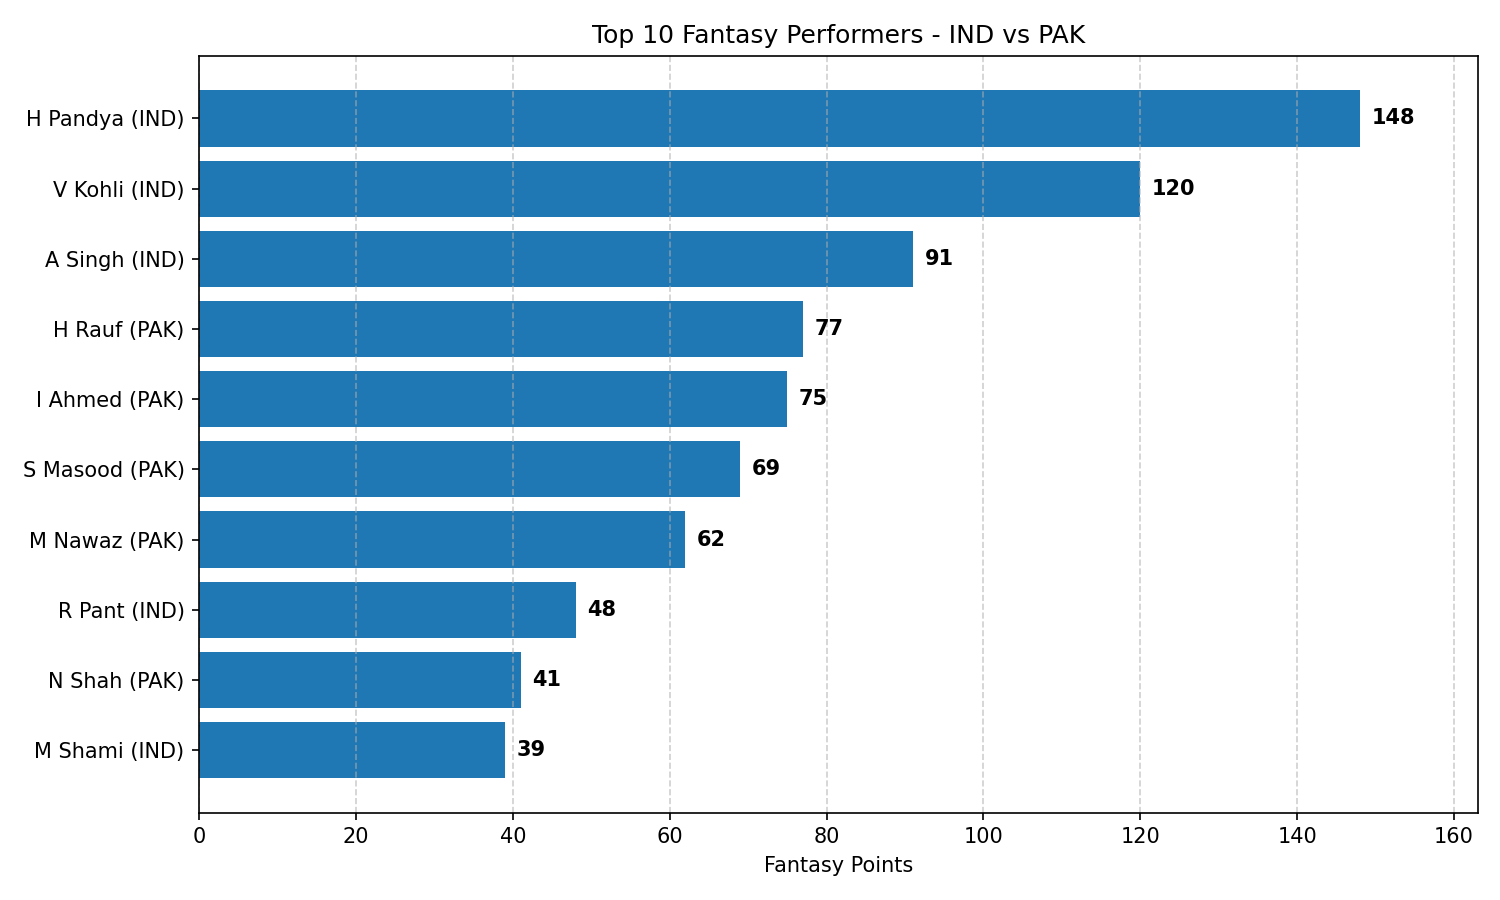

In [20]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# STEP 1: Rules
rules_config = {
    "general": {"playing_xi": 4},
    "batting": {
        "run": 1, "boundary_bonus": 1, "six_bonus": 2,
        "thirty_run_bonus": 4, "half_century_bonus": 8, "century_bonus": 16,
        "duck_penalty": -2, "min_balls_for_sr": 10,
        "strike_rate_tiers": [
            {"min": 170.01, "points": 6}, {"min": 150.01, "max": 170.0, "points": 4},
            {"min": 130.0, "max": 150.0, "points": 2}, {"min": 60.0, "max": 70.0, "points": -2},
            {"min": 50.0, "max": 59.99, "points": -4}, {"max": 49.99, "points": -6}
        ]
    },
    "bowling": {
        "wicket": 25, "lbw_bowled_bonus": 8, "maiden_over": 12,
        "three_wicket_bonus": 4, "four_wicket_bonus": 8, "five_wicket_bonus": 16,
        "min_overs_for_econ": 2.0,
        "economy_tiers": [
            {"max": 4.99, "points": 6}, {"min": 5.0, "max": 5.99, "points": 4},
            {"min": 6.0, "max": 7.0, "points": 2}, {"min": 10.0, "max": 11.0, "points": -2},
            {"min": 11.01, "max": 12.0, "points": -4}, {"min": 12.01, "points": -6}
        ]
    },
    "fielding": {"catch": 8, "three_catch_bonus": 4, "stumping": 12, "run_out_direct": 12, "run_out_indirect": 6},
    "multipliers": {"captain": 2.0, "vice_captain": 1.5}
}

with open("rules_t20.json", "w") as f:
    json.dump(rules_config, f, indent=4)

# STEP 2: Match Data
sample_players = [
    [101, "R Sharma", "IND", "BAT", 1, 15, 11, 2, 1, 1, 0.0, 0, 0, 0, 0, 1, 0, 0, 0],
    [102, "V Kohli", "IND", "BAT", 1, 82, 53, 6, 4, 0, 0.0, 0, 0, 0, 0, 1, 0, 0, 0],
    [103, "S Yadav", "IND", "BAT", 1, 15, 10, 2, 0, 1, 0.0, 0, 0, 0, 0, 1, 0, 0, 0],
    [104, "R Pant", "IND", "WK", 1, 14, 12, 2, 0, 1, 0.0, 0, 0, 0, 0, 2, 1, 0, 0],
    [105, "H Pandya", "IND", "AR", 1, 40, 37, 1, 2, 1, 4.0, 0, 30, 3, 1, 1, 0, 0, 0],
    [106, "A Patel", "IND", "AR", 1, 2, 3, 0, 0, 1, 1.0, 0, 21, 0, 0, 0, 0, 0, 0],
    [107, "D Karthik", "IND", "WK", 1, 1, 2, 0, 0, 1, 0.0, 0, 0, 0, 0, 0, 0, 0, 0],
    [108, "R Ashwin", "IND", "AR", 1, 1, 1, 0, 0, 0, 3.0, 0, 23, 0, 0, 0, 0, 0, 1],
    [109, "B Kumar", "IND", "BOWL", 1, 0, 0, 0, 0, 0, 4.0, 0, 22, 1, 0, 0, 0, 0, 0],
    [110, "M Shami", "IND", "BOWL", 1, 0, 0, 0, 0, 0, 4.0, 0, 25, 1, 1, 0, 0, 0, 0],
    [111, "A Singh", "IND", "BOWL", 1, 0, 0, 0, 0, 0, 4.0, 0, 32, 3, 1, 0, 0, 0, 0],
    [201, "B Azam", "PAK", "BAT", 1, 0, 1, 0, 0, 1, 0.0, 0, 0, 0, 0, 1, 0, 0, 0],
    [202, "M Rizwan", "PAK", "WK", 1, 4, 12, 0, 0, 1, 0.0, 0, 0, 0, 0, 1, 0, 0, 0],
    [203, "S Masood", "PAK", "BAT", 1, 52, 42, 5, 0, 0, 0.0, 0, 0, 0, 0, 0, 0, 0, 0],
    [204, "I Ahmed", "PAK", "AR", 1, 51, 34, 2, 4, 1, 0.0, 0, 0, 0, 0, 0, 0, 0, 0],
    [205, "S Khan", "PAK", "AR", 1, 5, 6, 0, 0, 1, 4.0, 0, 21, 0, 0, 1, 0, 0, 0],
    [206, "H Ali", "PAK", "BAT", 1, 1, 2, 0, 0, 1, 0.0, 0, 0, 0, 0, 1, 0, 0, 0],
    [207, "M Nawaz", "PAK", "AR", 1, 9, 6, 1, 0, 1, 4.0, 0, 42, 2, 0, 0, 0, 0, 0],
    [208, "A Ali", "PAK", "BAT", 1, 2, 3, 0, 0, 1, 0.0, 0, 0, 0, 0, 1, 0, 0, 0],
    [209, "S Afridi", "PAK", "BOWL", 1, 16, 8, 1, 1, 0, 4.0, 0, 34, 0, 0, 0, 0, 0, 0],
    [210, "N Shah", "PAK", "BOWL", 1, 0, 0, 0, 0, 0, 4.0, 0, 23, 1, 1, 0, 0, 0, 0],
    [211, "H Rauf", "PAK", "BOWL", 1, 13, 6, 0, 1, 0, 4.0, 0, 36, 2, 1, 0, 0, 0, 0]
]

columns = [
    "player_id", "player_name", "team", "role", "in_playing_xi",
    "runs", "balls_faced", "fours", "sixes", "is_out",
    "overs_bowled", "maidens", "runs_conceded", "wickets", "lbw_bowled_wickets",
    "catches", "stumpings", "run_outs_direct", "run_outs_indirect"
]
pd.DataFrame(sample_players, columns=columns).to_csv("match_data.csv", index=False)

# STEP 3: Scoring Engine
class FantasyScoringEngine:
    def __init__(self, rules_path: str):
        with open(rules_path, "r") as f:
            self.rules = json.load(f)

    def _apply_tier_rules(self, series, eligible_mask, tiers):
        conditions, choices = [], []
        for tier in tiers:
            cond = eligible_mask.copy()
            if "min" in tier: cond &= series >= tier["min"]
            if "max" in tier: cond &= series <= tier["max"]
            conditions.append(cond)
            choices.append(tier["points"])
        return np.select(conditions, choices, default=0)

    def calculate_batting_points(self, df):
        r = self.rules["batting"]
        pts = df["runs"] * r["run"] + df["fours"] * r["boundary_bonus"] + df["sixes"] * r["six_bonus"]
        pts += np.select([df["runs"] >= 100, df["runs"] >= 50, df["runs"] >= 30], [r["century_bonus"], r["half_century_bonus"], r["thirty_run_bonus"]], default=0)
        pts += np.where((df["runs"] == 0) & (df["is_out"] == 1) & (df["role"] != "BOWL"), r["duck_penalty"], 0)
        sr = np.where(df["balls_faced"] > 0, (df["runs"] / df["balls_faced"]) * 100, 0.0)
        eligible_sr = (df["balls_faced"] >= r["min_balls_for_sr"]) & (df["role"] != "BOWL")
        pts += self._apply_tier_rules(pd.Series(sr, index=df.index), eligible_sr, r["strike_rate_tiers"])
        return pts

    def calculate_bowling_points(self, df):
        r = self.rules["bowling"]
        pts = df["wickets"] * r["wicket"] + df["lbw_bowled_wickets"] * r["lbw_bowled_bonus"] + df["maidens"] * r["maiden_over"]
        pts += np.select([df["wickets"] >= 5, df["wickets"] == 4, df["wickets"] == 3], [r["five_wicket_bonus"], r["four_wicket_bonus"], r["three_wicket_bonus"]], default=0)
        whole_overs = np.floor(df["overs_bowled"])
        true_overs = whole_overs + (np.round((df["overs_bowled"] - whole_overs) * 10) / 6.0)
        econ = np.where(true_overs > 0, df["runs_conceded"] / true_overs, 0.0)
        pts += self._apply_tier_rules(pd.Series(econ, index=df.index), true_overs >= r["min_overs_for_econ"], r["economy_tiers"])
        return pts

    def calculate_fielding_points(self, df):
        r = self.rules["fielding"]
        return df["catches"] * r["catch"] + np.where(df["catches"] >= 3, r["three_catch_bonus"], 0) + df["stumpings"] * r["stumping"] + df["run_outs_direct"] * r["run_out_direct"] + df["run_outs_indirect"] * r["run_out_indirect"]

    def score_match(self, df):
        res = df.copy()
        res["xi_pts"] = np.where(res["in_playing_xi"] == 1, self.rules["general"]["playing_xi"], 0)
        res["bat_pts"] = self.calculate_batting_points(res)
        res["bowl_pts"] = self.calculate_bowling_points(res)
        res["field_pts"] = self.calculate_fielding_points(res)
        res["total_points"] = res["xi_pts"] + res["bat_pts"] + res["bowl_pts"] + res["field_pts"]
        return res

    def score_user_team(self, scored_df, player_ids, captain_id, vice_captain_id):
        team_df = scored_df[scored_df["player_id"].isin(player_ids)].copy()
        team_df["multiplier"] = np.select([team_df["player_id"] == captain_id, team_df["player_id"] == vice_captain_id], [self.rules["multipliers"]["captain"], self.rules["multipliers"]["vice_captain"]], default=1.0)
        team_df["final_points"] = team_df["total_points"] * team_df["multiplier"]
        return {"total_fantasy_points": float(team_df["final_points"].sum()), "breakdown": team_df[["player_name", "team", "role", "total_points", "multiplier", "final_points"]]}

# STEP 4: Run & Plot
match_df = pd.read_csv("match_data.csv")
engine = FantasyScoringEngine("rules_t20.json")
scored_df = engine.score_match(match_df)

print("=== FULL MATCH FANTASY LEADERBOARD ===")
leaderboard = scored_df[["player_id", "player_name", "team", "role", "bat_pts", "bowl_pts", "field_pts", "total_points"]].sort_values(by="total_points", ascending=False).reset_index(drop=True)
print(leaderboard.to_string(index=False))

user_team_ids = list((101, 102, 104, 105, 111, 202, 203, 204, 207, 210, 211))
user_result = engine.score_user_team(scored_df, user_team_ids, captain_id=102, vice_captain_id=105)
print(f"\n=== USER TEAM SCORE: {user_result['total_fantasy_points']} PTS ===")
print(user_result["breakdown"].to_string(index=False))

print("\n=== TOP 10 FANTASY PERFORMERS CHART ===")
top_10 = leaderboard.head(10).iloc[::-1]
labels = top_10["player_name"] + " (" + top_10["team"] + ")"

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, top_10["total_points"], color="#1f77b4")
ax.set_xlabel("Fantasy Points")
ax.set_title("Top 10 Fantasy Performers - IND vs PAK")
ax.set_xlim(0, top_10["total_points"].max() + 15)
ax.grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars:
    ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2, f"{int(bar.get_width())}", va="center", fontweight="bold")

plt.tight_layout()
plt.savefig("top_10_chart.png", dpi=150)
plt.close(fig)
display(Image("top_10_chart.png"))